# Spatial Slice Plotting

This tutorial demonstrates how to handle the spatial voxel grid objects for the exploration of hypothalamus.

In this notebook, we will:
1. Load the smoothed voxel probabilities and region masks.
2. Explore the distribution of specific cell clusters (e.g., Tanycytes) across slices.
3. Visualize probability distributions, counts, and relative mass.


Requirements:
1. `matplotlib`, `numpy` and `zarr>3.1` python packages.
2. The spatial Zarr object (if in .tar format, then decompress it). 

In [1]:
# Enable automatic reloading of modules during interactive work (optional)
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt

import zarr # >3.1
import numpy as np

In [ ]:
# Set the path to each the required objects
FP_SPATIAL_ZARR = r'REPLACE FILEPATH HERE'

## Loading the voxel datasets
 
We will load the datasets stored in **Zarr** format.

In [5]:
voxel_store = zarr.open(FP_SPATIAL_ZARR, mode='r')
voxel_store.tree()

/
├── L1
│   ├── abc-like (6,) StringDType()
│   ├── descr (6,) StringDType()
│   ├── flags (6,) StringDType()
│   ├── ids (6,) StringDType()
│   ├── mass (6, 168, 144, 107) float32
│   ├── prob (6, 168, 144, 107) float32
│   └── rel_mass (6, 168, 144, 107) float32
├── L2
│   ├── abc-like (82,) StringDType()
│   ├── descr (82,) StringDType()
│   ├── flags (82,) StringDType()
│   ├── ids (82,) StringDType()
│   ├── mass (82, 168, 144, 107) float32
│   ├── prob (82, 168, 144, 107) float32
│   └── rel_mass (82, 168, 144, 107) float32
├── L3
│   ├── abc-like (274,) StringDType()
│   ├── descr (274,) StringDType()
│   ├── flags (274,) StringDType()
│   ├── ids (274,) StringDType()
│   ├── mass (274, 168, 144, 107) float32
│   ├── prob (274, 168, 144, 107) float32
│   └── rel_mass (274, 168, 144, 107) float32
├── L4
│   ├── abc-like (716,) StringDType()
│   ├── descr (716,) StringDType()
│   ├── flags (716,) StringDType()
│   ├── ids (716,) StringDType()
│   ├── mass (716, 168, 144, 107) float32
│   ├── prob (716, 168, 144, 107) float32
│   └── rel_mass (716, 168, 144, 107) float32
├── L5
│   ├── abc-like (932,) StringDType()
│   ├── descr (932,) StringDType()
│   ├── flags (932,) StringDType()
│   ├── ids (932,) StringDType()
│   ├── mass (932, 168, 144, 107) float32
│   ├── prob (932, 168, 144, 107) float32
│   └── rel_mass (932, 168, 144, 107) float32
├── bbox
│   ├── ccf_mm
│   │   ├── max (3,) float32
│   │   └── min (3,) float32
│   ├── shape (3,) float32
│   └── voxel_25_um
│       ├── max (3,) float32
│       └── min (3,) float32
├── counts (168, 144, 107) float32
├── evidence (168, 144, 107) float32
├── latent_embedding (45, 168, 144, 107) float32
└── region
    ├── acronyms (176,) StringDType()
    ├── ids (176,) int32
    ├── region_labels (168, 144, 107) uint32
    └── region_masks (176, 168, 144, 107) bool

## Visualizing regions of interest

Let's visualize the outlines of the **full hypothalamus (HY)** and the **arcuate nucleus (ARH)** on a coronal slice.  
This will provide anatomical context for our subsequent cluster visualizations.  

There are 193 distinct structures within the defined bounding box of the HypoMap3D spatial datasts based on CCFv3 mouse brian atlas.


In [6]:
# Accessing region aconyms
print(f"First ten region acronyms in index order: {voxel_store['region']['acronyms'][:10]}")

# Similarly these can accessed by abc region id
print(f"First ten region ids in index order: {voxel_store['region']['ids'][:10]}")

First ten region acronyms in index order: ['TMv' 'int' 'IF' 'PT' 'AAA' 'PVa' 'PVH' 'mfb' 'ACB' 'MT']
First ten region ids in index order: [ 1  6 12 15 23 30 38 54 56 58]


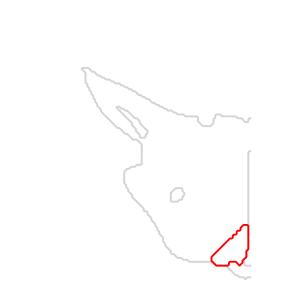

In [8]:
slice_x_idx = 109 # coronal slice index

fig, ax = plt.subplots(1, 1, figsize=(4,4), dpi=90)

ax.yaxis.set_inverted(True)  # Flip Y-axis for correct orientation
ax.axis('equal')  # Maintain aspect ratio
ax.axis('off')  # Hide axis ticks

# Overlay the region masks
for region, color in zip(['HY', 'ARH'], ['lightgrey', 'red']):
    
    region_idx = list(voxel_store['region']['acronyms']).index(region) # get indices of desired structures
    slice_mask = voxel_store['region']['region_masks'][region_idx, slice_x_idx, :, :] # load structure masks
    ax.contour(slice_mask, colors=color)

plt.show()
plt.close(fig);

## Visualizing a single cell cluster
 
We will explore the spatial distribution of **NN3-29 Tanycyte_alpha1**.
Steps:
1. Identify the coronal slice with the highest abundance of this cluster.
2. Visualize the abundance across slices as a line chart.
3. Overlay the cluster probability on the anatomical mask.

In [9]:
target_cluster = 'NN3-27 Tanycyte_alpha1'
cluster_idx = list(voxel_store['L3']['descr']).index(target_cluster)
voxel_grid = voxel_store['L3']['mass'][cluster_idx, ...]  # Full 3D voxel grid
voxel_grid.shape

(168, 144, 107)

Slice 95 has the highest abundance for NN3-27 Tanycyte_alpha1.


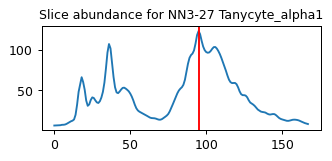

In [11]:
# Compute slice-wise abundance by summing across Y and Z axes
slice_abundance = np.nansum(voxel_grid, axis=(1,2))
slice_x_idx = np.argmax(slice_abundance)
print(f"Slice {slice_x_idx} has the highest abundance for {target_cluster}.")

# Line plot of slice abundance
fig, ax = plt.subplots(1, 1, figsize=(4,1.5), dpi=90)
ax.plot(slice_abundance)
ax.set_title(f"Slice abundance for {target_cluster}", fontdict={'size': 10})
ax.axvline(slice_x_idx, color='red')  # Highlight most abundant slice

plt.show()
plt.close(fig)

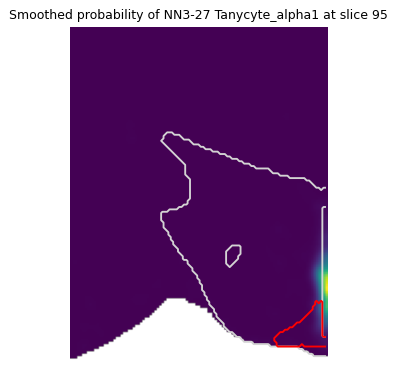

In [12]:
# Plot smoothed probability for the identified slice
fig, ax = plt.subplots(1, 1, figsize=(5,5), dpi=90)
ax.yaxis.set_inverted(True)
ax.axis('equal')
ax.axis('off')

# Display probability as an image
voxel_slice = voxel_grid[slice_x_idx]
ax.imshow(voxel_slice, cmap='viridis')

# Overlay anatomical regions
for region, color in zip(['HY', 'ARH'], ['lightgrey', 'red']):
    region_idx = list(voxel_store['region']['acronyms']).index(region) # get indices of desired structures
    slice_mask = voxel_store['region']['region_masks'][region_idx, slice_x_idx, :, :] # load structure masks
    ax.contour(slice_mask, colors=color)

ax.set_title(f"Smoothed probability of {target_cluster} at slice {slice_x_idx}", fontdict={'size': 10})

plt.show()
plt.close(fig)

## Visualizing multiple Tanycyte clusters
 
Combine **NN3-25, NN3-26, NN3-27 Tanycytes** into a single RGB image for visual comparison.  
Each channel corresponds to a different clusters' mass:  
- Red: NN3-27  
- Green: NN3-26  
- Blue: NN3-25  

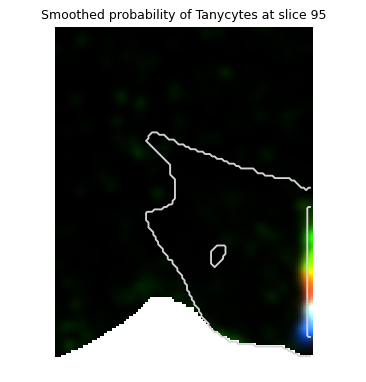

In [27]:
slice_x_idx # previously defined as most abundant NN3-27 slice (see above)

fig, ax = plt.subplots(1, 1, figsize=(5,5), dpi=90)
ax.yaxis.set_inverted(True)
ax.axis('equal')
ax.axis('off')

_, Y, Z = np.array(voxel_store['bbox']['shape'], dtype=int)
image = np.zeros((Y, Z, 3))

for i, cluster in enumerate(['NN3-27', 'NN3-26', 'NN3-25']):
    cluster_idx = list(voxel_store['L3']['ids']).index(cluster)
    voxel_slice = voxel_store['L3']['mass'][cluster_idx, slice_x_idx, :, :]
    image[..., i] = voxel_slice

# Visual normalization pre-processing
percentile_vmaxes = np.nanpercentile(image, 99.8, axis=(0, 1), keepdims=True)
processed_image = np.clip((image / percentile_vmaxes), 0, 1)

ax.imshow(processed_image)

# Overlay hypothalamus outline
region_idx = list(voxel_store['region']['acronyms']).index('HY')
slice_mask = voxel_store['region']['region_masks'][region_idx, slice_x_idx, :, :]
ax.contour(slice_mask, colors='lightgrey')

ax.set_title(f"Smoothed probability of Tanycytes at slice {slice_x_idx}", fontdict={'size': 10})

plt.show()
plt.close(fig)